In [18]:
from typing import Dict, Any, List
from core import settings, utils, plotting
from core.io import EpochIO
import numpy as np
import torch
import os
from scipy.stats import sem
from collections import defaultdict
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

In [19]:
def get_logged(data_dict: Dict[str, Dict[str, Any]]):
    """
    Log tensors in data_dict

    Args:
        data_dict (Dict[Dict[str, Any]]): Nested dictionary containing subject data.
        condition (str): The condition to extract metrics for.

    Returns:
        List[float]: List of logged metrics for the specified condition across subjects.
    """

    logged = {}
    for subj in data_dict.keys():
        logged.setdefault(subj, {})
        for cond in data_dict[subj].keys():
            logged[subj].setdefault(cond, [])
            mags = data_dict[subj][cond]
            mags_data = mags.clone().detach()
            mags_data = utils.cut_to_size(mags_data, settings.WINDOW_SIZE)
            logged[subj][cond] = 20*torch.log10(mags_data + 1e-7) # add small value to avoid log(0)
    return logged



def subject_volatilities(wavelet_dir, condition="global"):
    """Per-subject mean dB volatility (global + per band), streaming one file at a time."""
    per_subj = defaultdict(lambda: defaultdict(list))
    band_idx = {name: np.where((settings.FREQS >= lo) & (settings.FREQS <= hi))[0]
                for name, (lo, hi) in settings.FREQ_BANDS.items()}
    for f in wavelet_dir.glob(f"*_{condition}_wavelet*.pt"):
        subj = f.name.split("_")[0]
        x = 20 * torch.log10(torch.load(f) + 1e-7)
        row_std = x.std(dim=-1, unbiased=False).numpy()        # (ch, freq) temporal std
        per_subj[subj]["global"].append(row_std.mean())
        for name, idx in band_idx.items():
            per_subj[subj][name].append(row_std[:, idx].mean())
    return {s: {b: np.mean(v) for b, v in bands.items()} for s, bands in per_subj.items()}

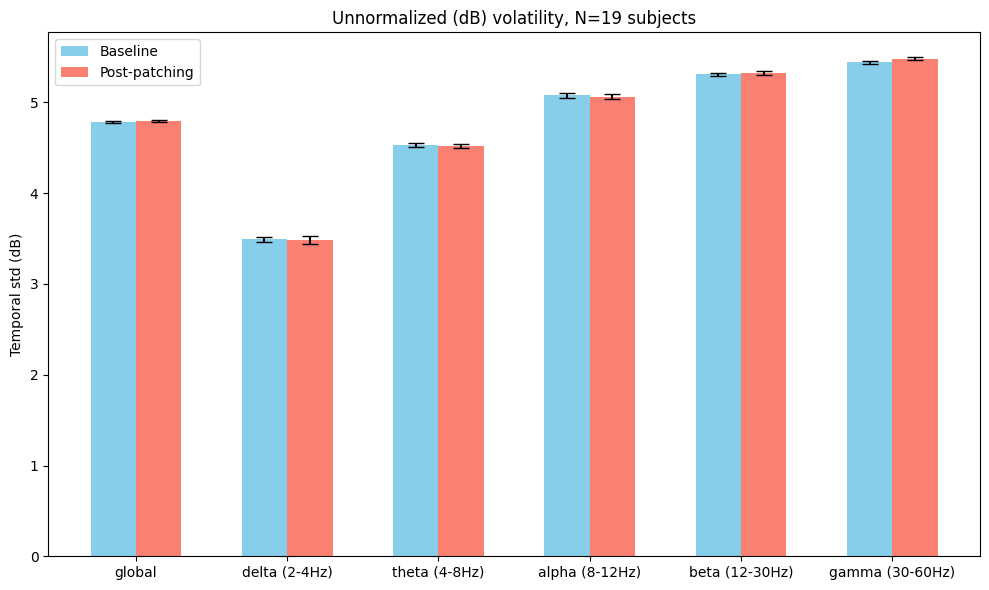

In [20]:


vol_b = subject_volatilities(settings.FINETUNE_WAVELET_DIR)
vol_p = subject_volatilities(settings.PATCH_WAVELET_DIR)
subjects = sorted(set(vol_b) & set(vol_p))                     # paired: both sessions only
bands = ["global", *settings.FREQ_BANDS]

pre  = np.array([[vol_b[s][b] for b in bands] for s in subjects])
post = np.array([[vol_p[s][b] for b in bands] for s in subjects])

fig, ax = plotting.plot_grouped_bar(
    x_text=bands, width=0.3,
    means=[pre.mean(0), post.mean(0)], sems=[sem(pre), sem(post)],
    labels=["Baseline", "Post-patching"],
    title=f"Unnormalized (dB) volatility, N={len(subjects)} subjects", y_label="Temporal std (dB)")
plotting.save_button(fig, save_dir=settings.PLOT_DIR/"signal_analysis/volatility", default_name="volatility_comparison")






In [21]:
import pandas as pd
from scipy.stats import ttest_rel


STAT_LABELS = {
    "volatility": "Temporal std (dB)",
    "inter_freq_std": "Inter-frequency std (dB)",
    "inter_channel_std": "Inter-channel std (dB)",
    "total_std": "Total std (dB)",
    "normalized_volatility": "Normalized volatility (a.u.)",
}


def subject_signal_stats(wavelet_dir, condition="global"):
    """
    Per-subject means of dB signal statistics (global + per band), streaming one file at a time.
    Row = one (channel, frequency) time course of the un-normalized dB wavelet magnitude.
      volatility:            mean temporal std of the rows
      inter_freq_std:        std across frequencies of the time-averaged spectrum, averaged over channels
      inter_channel_std:     std across channels of the time-averaged spectrum, averaged over frequencies
      total_std:             std over all channels, frequencies and time points
      normalized_volatility: volatility / global total_std (the scale the model's targets are z-scored to)
    """
    per_subj = {stat: defaultdict(lambda: defaultdict(list)) for stat in STAT_LABELS}
    band_idx = {"global": np.arange(len(settings.FREQS))}
    band_idx.update({name: np.where((settings.FREQS >= lo) & (settings.FREQS <= hi))[0]
                     for name, (lo, hi) in settings.FREQ_BANDS.items()})
    for f in wavelet_dir.glob(f"*_{condition}_wavelet*.pt"):
        subj = f.name.split("_")[0]
        x = (20 * torch.log10(torch.load(f) + 1e-7)).numpy()  # (ch, freq, time)
        row_mean = x.mean(axis=-1)  # (ch, freq) time-averaged spectrum
        row_std = x.std(axis=-1)    # (ch, freq) temporal std
        global_total_std = x.std()
        for band, idx in band_idx.items():
            vol = row_std[:, idx].mean()
            per_subj["volatility"][subj][band].append(vol)
            per_subj["inter_freq_std"][subj][band].append(row_mean[:, idx].std(axis=1).mean())
            per_subj["inter_channel_std"][subj][band].append(row_mean[:, idx].std(axis=0).mean())
            per_subj["total_std"][subj][band].append(x[:, idx].std())
            per_subj["normalized_volatility"][subj][band].append(vol / global_total_std)
    return {stat: {s: {b: np.mean(v) for b, v in bands.items()} for s, bands in subj_dict.items()}
            for stat, subj_dict in per_subj.items()}


def paired_summary(stats_b, stats_p, stat, bands):
    """Paired pre/post comparison across subjects: mean change, % change, t, p and d_z per band."""
    subjects = sorted(set(stats_b[stat]) & set(stats_p[stat]))
    rows = []
    for band in bands:
        pre = np.array([stats_b[stat][s][band] for s in subjects])
        post = np.array([stats_p[stat][s][band] for s in subjects])
        d = post - pre
        t, p = ttest_rel(post, pre)
        rows.append({"band": band, "pre": pre.mean(), "post": post.mean(), "mean_diff": d.mean(),
                     "pct_change": 100 * d.mean() / pre.mean(), "t": t, "p": p, "d_z": d.mean() / d.std(ddof=1)})
    return pd.DataFrame(rows).set_index("band"), subjects


In [22]:
stats_b = subject_signal_stats(settings.FINETUNE_WAVELET_DIR)
stats_p = subject_signal_stats(settings.PATCH_WAVELET_DIR)
bands = ["global", *settings.FREQ_BANDS]

summaries = {}
for stat in STAT_LABELS:
    summaries[stat], subjects = paired_summary(stats_b, stats_p, stat, bands)
    print(f"== {stat} (N={len(subjects)} subjects)")
    display(summaries[stat].round(4))


== volatility (N=19 subjects)


,pre,post,mean_diff,pct_change,t,p,d_z
band,,,,,,,
global,4.7893,4.7965,0.0072,0.1508,0.4115,0.6856,0.0944
delta (2-4Hz),3.4917,3.4841,-0.0076,-0.2175,-0.1432,0.8878,-0.0328
theta (4-8Hz),4.5339,4.5236,-0.0103,-0.2266,-0.3387,0.7388,-0.0777
alpha (8-12Hz),5.0784,5.0650,-0.0134,-0.2646,-0.4987,0.6241,-0.1144
beta (12-30Hz),5.3093,5.3239,0.0146,0.2747,0.8744,0.3934,0.2006
gamma (30-60Hz),5.4409,5.4825,0.0416,0.7653,3.2168,0.0048,0.7380


== inter_freq_std (N=19 subjects)


,pre,post,mean_diff,pct_change,t,p,d_z
band,,,,,,,
global,6.3158,6.2578,-0.0580,-0.9187,-0.4949,0.6267,-0.1135
delta (2-4Hz),2.8104,2.7338,-0.0767,-2.7278,-2.3348,0.0313,-0.5356
theta (4-8Hz),2.2121,2.2037,-0.0084,-0.3809,-0.4351,0.6686,-0.0998
alpha (8-12Hz),1.3702,1.3646,-0.0056,-0.4054,-0.2562,0.8007,-0.0588
beta (12-30Hz),2.2576,2.4009,0.1433,6.3454,2.6886,0.0150,0.6168
gamma (30-60Hz),1.5060,1.5212,0.0152,1.0077,0.3678,0.7173,0.0844


== inter_channel_std (N=19 subjects)


,pre,post,mean_diff,pct_change,t,p,d_z
band,,,,,,,
global,3.2238,3.2867,0.0630,1.9534,1.2296,0.2347,0.2821
delta (2-4Hz),4.1323,4.2168,0.0845,2.0448,1.2109,0.2416,0.2778
theta (4-8Hz),3.2973,3.3822,0.0849,2.5751,1.3651,0.1890,0.3132
alpha (8-12Hz),2.7722,2.8415,0.0693,2.5010,1.3548,0.1922,0.3108
beta (12-30Hz),2.6166,2.6841,0.0675,2.5802,1.0080,0.3268,0.2312
gamma (30-60Hz),3.3627,3.3720,0.0093,0.2778,0.0945,0.9258,0.0217


== total_std (N=19 subjects)


,pre,post,mean_diff,pct_change,t,p,d_z
band,,,,,,,
global,8.4813,8.4718,-0.0095,-0.1115,-0.1081,0.9151,-0.0248
delta (2-4Hz),6.0502,6.0500,-0.0001,-0.0025,-0.0019,0.9985,-0.0004
theta (4-8Hz),6.0807,6.1173,0.0366,0.6011,0.7124,0.4854,0.1634
alpha (8-12Hz),6.0636,6.0862,0.0226,0.3723,0.7488,0.4636,0.1718
beta (12-30Hz),6.3589,6.4595,0.1006,1.5819,3.8883,0.0011,0.8920
gamma (30-60Hz),6.6231,6.6797,0.0567,0.8560,1.2801,0.2168,0.2937


== normalized_volatility (N=19 subjects)


,pre,post,mean_diff,pct_change,t,p,d_z
band,,,,,,,
global,0.5698,0.5717,0.0019,0.3274,0.3436,0.7352,0.0788
delta (2-4Hz),0.4152,0.4152,0.0000,0.0026,0.0020,0.9985,0.0004
theta (4-8Hz),0.5391,0.5387,-0.0004,-0.0820,-0.0719,0.9435,-0.0165
alpha (8-12Hz),0.6040,0.6038,-0.0002,-0.0327,-0.0309,0.9757,-0.0071
beta (12-30Hz),0.6318,0.6344,0.0026,0.4142,0.3876,0.7029,0.0889
gamma (30-60Hz),0.6477,0.6539,0.0062,0.9594,0.9347,0.3623,0.2144


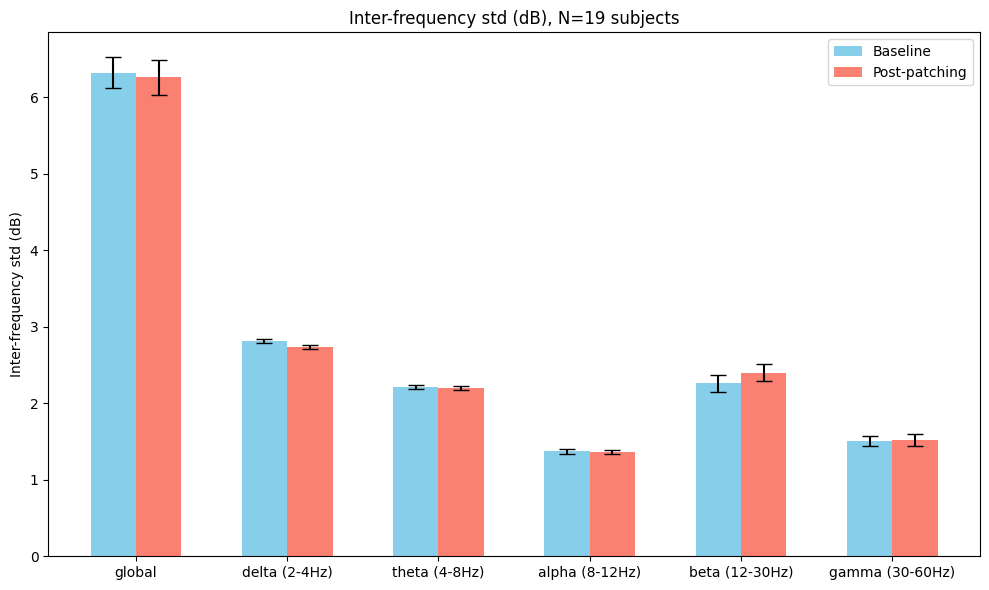

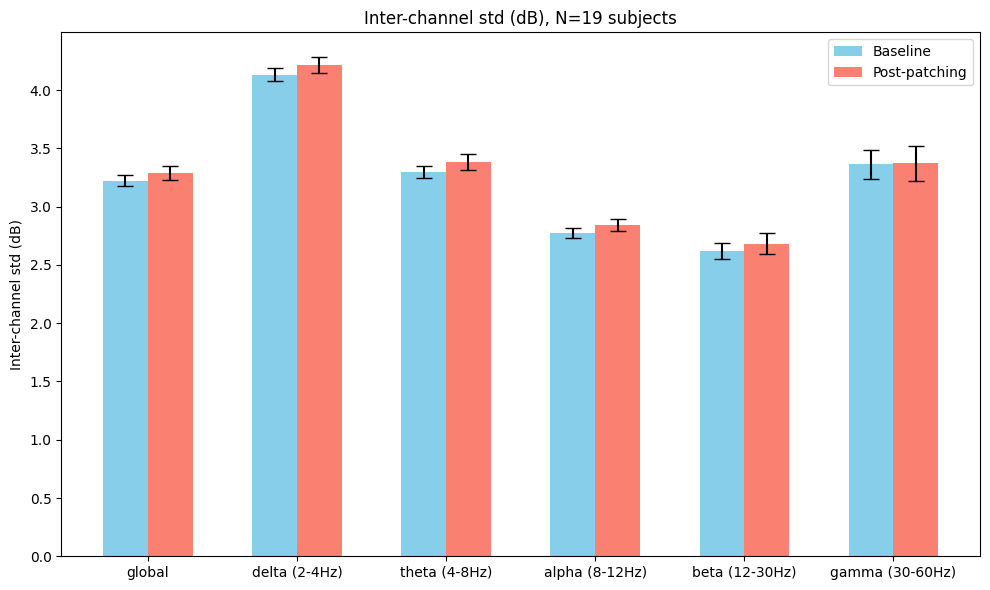

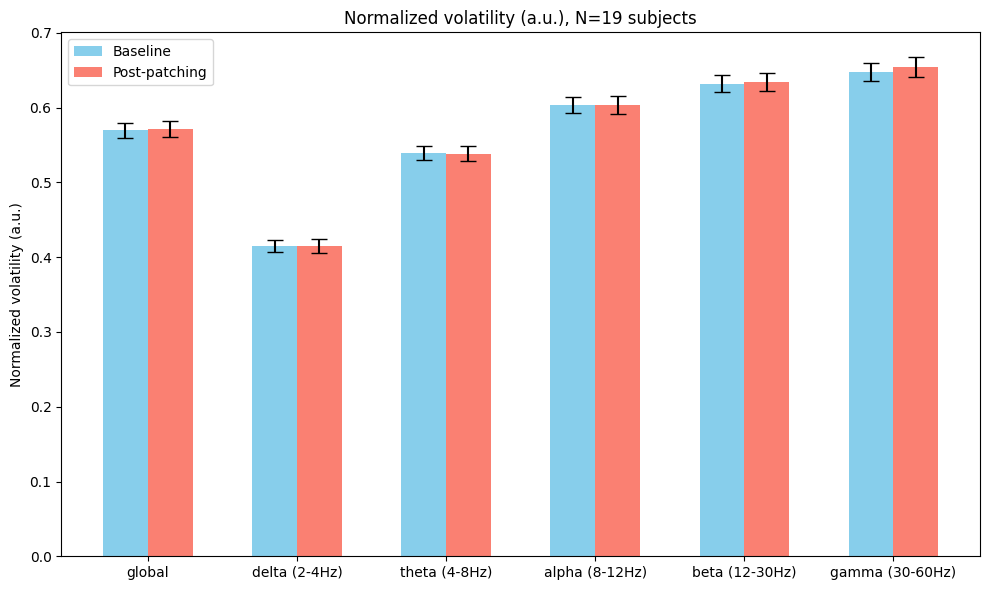

In [23]:
for stat in ["inter_freq_std", "inter_channel_std", "normalized_volatility"]:
    subjects = sorted(set(stats_b[stat]) & set(stats_p[stat]))
    pre = np.array([[stats_b[stat][s][b] for b in bands] for s in subjects])
    post = np.array([[stats_p[stat][s][b] for b in bands] for s in subjects])

    fig, ax = plotting.plot_grouped_bar(
        x_text=bands, width=0.3,
        means=[pre.mean(0), post.mean(0)], sems=[sem(pre), sem(post)],
        labels=["Baseline", "Post-patching"],
        title=f"{STAT_LABELS[stat]}, N={len(subjects)} subjects", y_label=STAT_LABELS[stat])
    plotting.save_button(fig, save_dir=settings.PLOT_DIR/"signal_analysis"/stat, default_name=f"{stat}_comparison")
